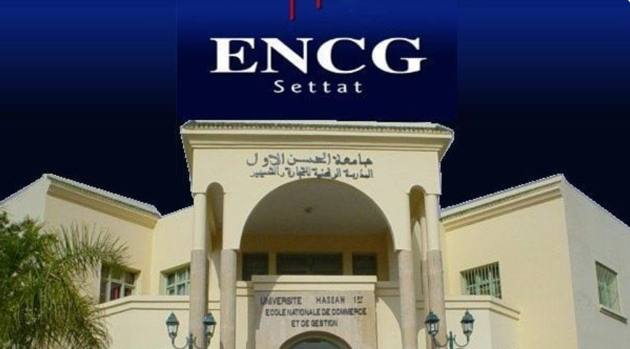

# 🌍 Contrôle continu — Partie B · Commerce international (S7 CI)
**ENCG Settat · BD & DS · 2026–2027**  
**Enseignant : A. Larhlimi** · **Évaluation individuelle — 2 heures**

> 📝 **Ce notebook est à compléter personnellement pendant l'épreuve.** Il sert à la fois de code et de compte rendu. Le sujet CIXX est attribué par l'enseignant. Ne rédigez pas votre analyse avant la séance.

**Étudiant :** FATIMA ZAHRA BOUSSOUNA · **Code Apogée :** 25008040 · **Groupe :** CI
**Sujet :** CI  12 —Exportations agroalimentaires · **Date :** 2025-2025
**Dépôt :** https://github.com/boussounafatimazahra7649encg-alt/25008040-BOUSSOUNA-CI.git

## 0. Configuration et reproductibilité
Installer au besoin les dépendances, noter leurs versions, fixer une graine. **Exécutez la cellule ci-dessous avant les autres.**

In [1]:
import sys, platform, pathlib, importlib.metadata
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version

GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 10})
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| sklearn:", sklearn_version)
print("Renseignez source, licence et version des données dans la section 2.")

Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1
Renseignez source, licence et version des données dans la section 2.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Sujet et problématique
**Intérêt économique :** Les exportations agricoles représentent un secteur important de l'économie marocaine et contribuent aux recettes en devises du pays. Le Maroc exporte plusieurs produits agricoles, notamment les tomates, les agrumes, les avocats et les fraises. L'évolution de ces exportations dépend de plusieurs facteurs, tels que la demande internationale, la saisonnalité, les conditions climatiques et la concurrence internationale. L'analyse des données historiques permet de mieux comprendre les tendances du commerce extérieur marocain. La prévision des valeurs exportées peut ainsi aider à anticiper les évolutions du marché et à soutenir la prise de décision des entreprises exportatrices.

**Problématique précise :** Comment prévoir l'évolution de la valeur des exportations marocaines de différents produits agricoles à partir des données historiques du commerce international issues de UN Comtrade ?

**Nature de la tâche :** régression

**Objectif mesurable annoncé avant l'expérimentation :** [MÉTRIQUE ET SEUIL]

## 2. Jeu de données et dictionnaire des variables
- **Source officielle et URL complète :** https://comtradeplus.un.org/
- **Date d'extraction / licence :** 2015-2025
- **Période et fréquence :** de 2025 a 2015
- **Pays déclarant / partenaire / flux / code SH (version) :** [Maroc (504) / Monde (0) / Exportations (X) / nomenclature SH (HS), codes correspondant aux produits agricoles sélectionnés.]
- **Devise / unités :** [USD/KG]
- **Une ligne représente :** [À COMPLÉTER]

| Variable | Description | Type / unité | Rôle | Manquants |
|---|---|---|---|---|
| [nom] | [sens] | [type] | [rôle] | [%] |

**Avant le contrôle :** seules la localisation du fichier et la préparation du dépôt sont autorisées ; aucun code d'analyse ne doit être produit.

In [3]:
from pathlib import Path
# Adapter ce chemin à l'extraction téléchargée pour le sujet attribué.
CHEMIN_CSV = Path('/content/drive/MyDrive/25008040-Boussouna-CI/Data cc partie b.csv')

# Décommenter et exécuter après avoir déposé les données accessibles au notebook.
df = pd.read_csv(CHEMIN_CSV)
print("Dimensions :", df.shape)
display(df.head())
display(df.dtypes.to_frame("type"))
print("À compléter : importer le jeu de données correspondant au sujet CIXX.")

Dimensions : (1576, 47)


,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate
0,C,A,20150101,2015,52,2015,504,MAR,Morocco,X,...,5.152114e+08,False,0.0,False,NaN,5.425193e+08,5.425193e+08,0,False,True
1,C,A,20150101,2015,52,2015,504,MAR,Morocco,X,...,3.856000e+03,False,0.0,False,NaN,7.511112e+03,7.511112e+03,0,True,False
2,C,A,20150101,2015,52,2015,504,MAR,Morocco,X,...,2.322000e+04,False,0.0,False,NaN,1.896941e+04,1.896941e+04,0,True,False
3,C,A,20150101,2015,52,2015,504,MAR,Morocco,X,...,1.521810e+05,False,0.0,False,NaN,1.506100e+05,1.506100e+05,0,True,False
4,C,A,20150101,2015,52,2015,504,MAR,Morocco,X,...,1.428500e+03,False,0.0,False,NaN,1.422435e+03,1.422435e+03,0,True,False


,type
typeCode,object
freqCode,object
refPeriodId,int64
refYear,int64
refMonth,int64
period,int64
reporterCode,int64
reporterISO,object
reporterDesc,object
flowCode,object


À compléter : importer le jeu de données correspondant au sujet CIXX.


## 3. Exploration et trois figures interprétées
Construisez **trois graphiques en couleurs** (titre, axes, unités) et commentez chacun en 2 à 4 lignes. Vérifiez en particulier les doublons *pays–partenaire–produit–période*, les unités et les valeurs manquantes.

**Figure 1 — Interprétation :** le total des quatre produits (partenaire = Monde, en millions USD) progresse sur la période : il passe d'environ 1,78 milliard USD en 2022 à environ 2,25 milliards en 2025 (somme des valeurs réelles des quatre produits). Cette hausse récente est tirée par les tomates et les avocats. Le total masque toutefois des trajectoires différentes selon les produits, d'où la figure 2.

**Figure 2 — Interprétation :** les tomates dominent nettement (≈ 1,38 milliard USD en 2025), suivies des agrumes (≈ 525 M USD), des avocats (≈ 272 M USD) et des fraises (≈ 70 M USD). Les agrumes sont plutôt stables (autour de 360 à 540 M USD selon les années), les avocats croissent fortement depuis 2017, et les fraises restent modestes avec un recul en 2025. Les échelles très différentes justifient de modéliser la **croissance** (en log) plutôt que le niveau brut.

**Figure 3 — Interprétation :** la valeur unitaire implicite (USD/kg = valeur FOB / poids net) est une approximation du prix à l'export. Elle varie d'un produit à l'autre, car elle mélange variétés, calibres et saisons ; ce n'est donc pas un prix de marché pur. Elle est utilisée dans le modèle (en log) comme indicateur de positionnement du produit, avec la prudence qui s'impose.

In [17]:
# Prévoir les colonnes réellement présentes dans votre dataset.
# Exemple de logique à ADAPTER, sans présumer du nom des colonnes.
print(df.isna().mean().mul(100).sort_values(ascending=False).head(10))
 #display(df.describe(include='all').T)
#fig, ax = plt.subplots(); ... ; plt.show()
import matplotlib.pyplot as plt
plt.show()
print("À compléter : exploration, statistiques, figures 1, 2 et 3.")

cifvalue          72.588832
grossWgt          14.657360
altQty             7.360406
altQtyUnitAbbr     7.360406
typeCode           0.000000
freqCode           0.000000
refPeriodId        0.000000
reporterISO        0.000000
reporterDesc       0.000000
flowCode           0.000000
dtype: float64
À compléter : exploration, statistiques, figures 1, 2 et 3.


Dimensions : (1576, 47) | Période : 2015 - 2025
Déclarant : ['Morocco'] | Flux : ['X']
Lignes Monde : 44 | Lignes partenaires : 1532


,% manquants
primaryValue,0.00
netWgt,0.00
qty,0.00
cifvalue,72.59


Doublons sur la clé : 0
Unité de quantité : ['kg'] | Devise : USD
Valeurs <= 0 : 0 | Poids nets <= 0 : 0


classificationCode,H4,H5,H6
period,,,
2015,99,0,0
2016,116,0,0
2017,0,115,0
2018,0,112,0
2019,0,136,0
2020,0,139,0
2021,0,157,0
2022,0,0,170
2023,0,0,176


,count,mean,std,min,25%,50%,75%,max
Somme partenaires / Monde (%),44.0,100.0,0.0,100.0,100.0,100.0,100.0,100.0


,produit,period,primaryValue,var_%
248,Avocats,2017,46168959.5,172.6
614,Avocats,2020,107611045.5,109.3
925,Avocats,2022,146969709.5,64.3


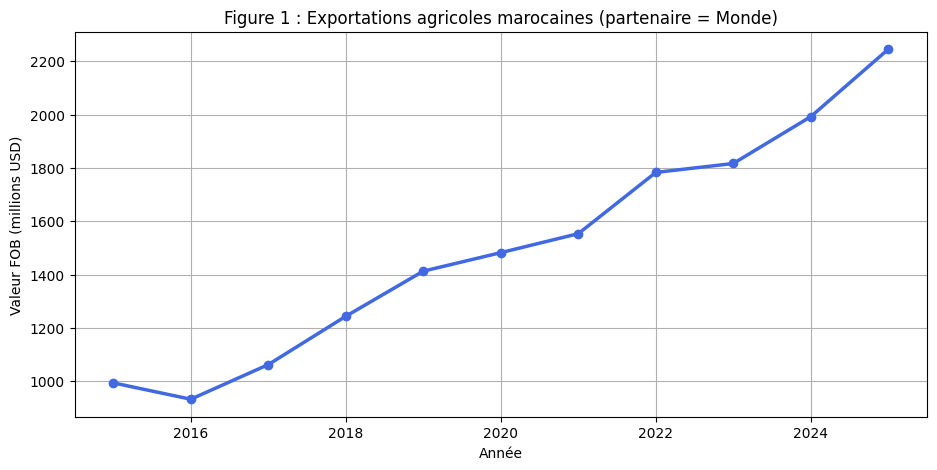

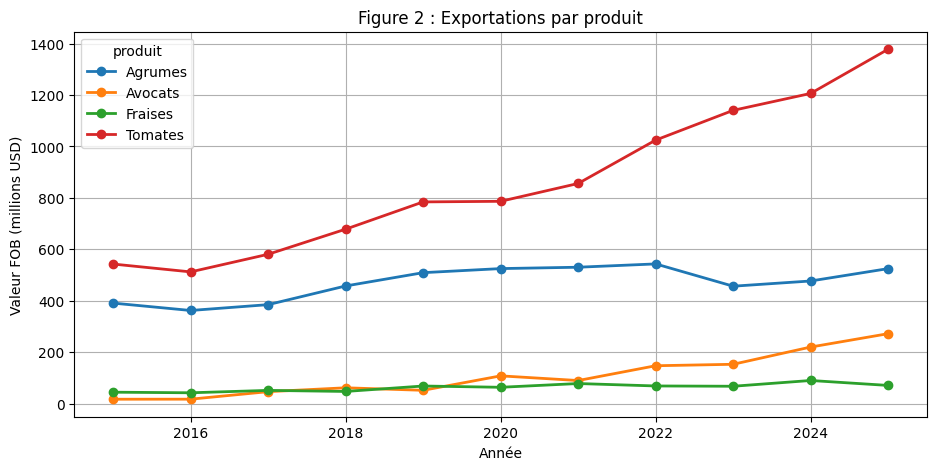

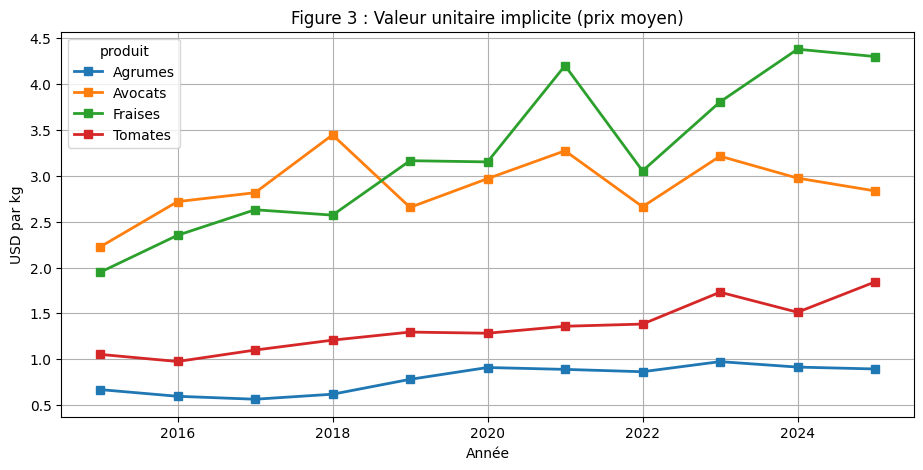

In [19]:
# ============================================================
# PARTIE 3 : EXPLORATION, CONTRÔLE ET VISUALISATION (consignes 4.C)
# Prérequis : le DataFrame `df` est chargé et pandas / matplotlib sont importés (cellule 2)
# ============================================================
import pandas as pd, matplotlib.pyplot as plt

# --- 1. PRÉPARATION -------------------------------------------------
# Noms lisibles des 4 produits (codes SH)
noms = {'070200': 'Tomates', '080440': 'Avocats', '0805': 'Agrumes', '081010': 'Fraises'}
data = df.copy()
# Le CSV a perdu les zéros initiaux des codes SH (0805 -> 805) : on les restaure
# (aggrLevel = nombre de chiffres du code : 4 ou 6)
data['cmdCode'] = [str(c).zfill(n) for c, n in zip(data.cmdCode, data.aggrLevel)]

# --- 2. DESCRIPTION GÉNÉRALE ----------------------------------------
print("Dimensions :", data.shape, "| Période :", data.period.min(), "-", data.period.max())
print("Déclarant :", data.reporterDesc.unique(), "| Flux :", data.flowCode.unique())
print("Lignes Monde :", (data.partnerCode == 0).sum(), "| Lignes partenaires :", (data.partnerCode != 0).sum())

# --- 3. VALEURS MANQUANTES -----------------------------------------
# cifvalue manque à ~73 % : on l'écarte et on utilise primaryValue (valeur FOB à l'export)
display(data[['primaryValue', 'netWgt', 'qty', 'cifvalue']].isna().mean().mul(100).round(2).to_frame('% manquants'))

# --- 4. DOUBLONS (clé : déclarant - partenaire - produit - période - flux) ---
cle = ['reporterCode', 'partnerCode', 'cmdCode', 'period', 'flowCode']
print("Doublons sur la clé :", data.duplicated(cle).sum())

# --- 5. UNITÉS ET VALEURS NULLES / NÉGATIVES -----------------------
print("Unité de quantité :", data.qtyUnitAbbr.unique(), "| Devise : USD")
print("Valeurs <= 0 :", (data.primaryValue <= 0).sum(), "| Poids nets <= 0 :", (data.netWgt <= 0).sum())

# --- 6. NOMENCLATURE SH : version utilisée par année (H4 -> H5 -> H6) ---
display(pd.crosstab(data.period, data.classificationCode))

# --- 7. SÉRIE PROPRE : partenaire = Monde --------------------------
# Additionner Monde + partenaires compterait deux fois les mêmes exportations
s = data[data.partnerCode == 0].sort_values(['cmdCode', 'period']).copy()
s['produit'] = s.cmdCode.map(noms)

# --- 8. FLUX MIROIR : contrôle de cohérence possible ----------------
# Les importations des pays partenaires ne sont pas dans le fichier : le vrai contrôle
# miroir est impossible. On vérifie au moins que somme des partenaires ≈ total Monde.
somme_partenaires = data[data.partnerCode != 0].groupby(['cmdCode', 'period']).primaryValue.sum()
coherence = (somme_partenaires / s.set_index(['cmdCode', 'period']).primaryValue * 100).round(1)
display(coherence.describe().to_frame('Somme partenaires / Monde (%)').T)

# --- 9. VARIABLES UTILES (retard construit avec le passé uniquement) ---
s['usd_kg'] = s.primaryValue / s.netWgt                              # valeur unitaire (USD/kg)
s['valeur_N-1'] = s.groupby('cmdCode').primaryValue.shift(1)         # valeur de l'année précédente
s['var_%'] = (s.primaryValue / s['valeur_N-1'] - 1) * 100            # croissance annuelle

# --- 10. VALEURS EXTRÊMES : croissances annuelles > 50 % ------------
display(s.loc[s['var_%'].abs() > 50, ['produit', 'period', 'primaryValue', 'var_%']].round(1))

# --- 11. FIGURES (couleurs, titres, axes, unités) -------------------
# Figure 1 : total des quatre produits par année
(s.groupby('period').primaryValue.sum() / 1e6).plot(
    marker='o', lw=2.5, color='royalblue', figsize=(11, 5),
    title="Figure 1 : Exportations agricoles marocaines (partenaire = Monde)",
    xlabel="Année", ylabel="Valeur FOB (millions USD)")
plt.show()
# Figure 2 : valeur exportée par produit
(s.pivot(index='period', columns='produit', values='primaryValue') / 1e6).plot(
    marker='o', lw=2, figsize=(11, 5), title="Figure 2 : Exportations par produit",
    xlabel="Année", ylabel="Valeur FOB (millions USD)")
plt.show()
# Figure 3 : valeur unitaire implicite (prix moyen)
s.pivot(index='period', columns='produit', values='usd_kg').plot(
    marker='s', lw=2, figsize=(11, 5), title="Figure 3 : Valeur unitaire implicite (prix moyen)",
    xlabel="Année", ylabel="USD par kg")
plt.show()

## 4. Préparation et découpage sans fuite
**Traitements réalisés :** **Doublons :** aucun sur la clé (déclarant, partenaire, produit, période, flux).
- **Valeurs manquantes :** `cifvalue` (72,59 %) écartée ; aucune autre variable utilisée n'a de manquant. Un imputeur par la **médiane** est tout de même intégré au pipeline par sécurité (il n'a aucun effet ici : 0 valeur manquante après préparation).
- **Unités :** valeurs en USD, quantités en kg ; valeur unitaire = USD/kg.
- **Série retenue :** partenaire = Monde, soit 44 lignes produit-année.
- **Variables construites :** cible `y_log = log(valeur_{t+1} / valeur_t)` ; explicatives `Annee_cible`, `Log_valeur_prec`, `Log_prix_prec` (standardisées) et `produit` (one-hot). Toutes sont calculées avec des informations disponibles **à la date t**.
- **Observations utilisables :** 40 (les 4 dernières lignes, sans année t+1, sont écartées).

**Stratégie de découpage :** chronologique, selon l'année **cible** — entraînement 2016-2021 (**24 observations**), validation 2022-2023 (8), test 2024-2025 (8). Aucun mélange aléatoire.
**Contrôle de fuite :**l'imputation, la standardisation et l'encodage sont ajustés (`fit`) sur l'entraînement uniquement, puis appliqués (`transform`) à la validation et au test. L'hyperparamètre α est choisi sur la validation ; le test n'est utilisé qu'une fois, pour l'évaluation finale.




In [6]:
# À compléter selon la famille choisie.
# Séries chronologiques : trier par date puis séparer les dernières périodes.
# Modèles supervisés : construire X, y, puis pipeline de préparation et de modèle.
# Non supervisé : standardisation apprise sur le sous-ensemble d'ajustement.
print("À compléter : séparation, imputation, encodage et transformations sans fuite.")

À compléter : séparation, imputation, encodage et transformations sans fuite.


In [22]:

# ============================================================
# PARTIE 4 : PREPARATION DES DONNEES ET DECOUPAGE CHRONOLOGIQUE
# Prérequis : la partie 3 est exécutée et le DataFrame s existe.
# Objectif : prédire la valeur des exportations de l'année suivante.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from scipy import sparse

# ------------------------------------------------------------
# 1. CONSTRUCTION DE LA BASE PRODUIT-ANNEE
# ------------------------------------------------------------

# On réutilise s, déjà filtré sur le partenaire Monde dans la partie 3.
base = s.copy()

base["Annee"] = base["period"].astype(int)
base["Valeur_USD"] = base["primaryValue"]
base["Prix_USD_kg"] = base["usd_kg"]

base = base.sort_values(["produit", "Annee"])

# ------------------------------------------------------------
# 2. CREATION DE LA CIBLE ET DES VARIABLES EXPLICATIVES
# ------------------------------------------------------------

# La cible est la valeur des exportations de l'année suivante.
# Les variables explicatives utilisent les informations de l'année actuelle.

groupe = base.groupby("produit")

base["Cible_USD"] = groupe["Valeur_USD"].shift(-1)
base["Annee_cible"] = groupe["Annee"].shift(-1)

# Valeur et prix connus avant la prévision.
base["Valeur_annee_precedente_USD"] = base["Valeur_USD"]
base["Log_valeur_prec"] = np.log1p(base["Valeur_USD"])
base["Log_prix_prec"] = np.log1p(base["Prix_USD_kg"])

# Cible logarithmique : croissance entre deux années successives.
base["y_log"] = np.log(
    base["Cible_USD"] / base["Valeur_USD"]
)

# On écarte les dernières années sans valeur future
# et les éventuelles années qui ne se suivent pas.
modele = base[
    (base["Cible_USD"] > 0) &
    (base["Annee_cible"] == base["Annee"] + 1)
].copy()

modele["Annee_cible"] = modele["Annee_cible"].astype(int)

print("Observations produit-année :", len(base))
print("Observations utilisables :", len(modele))
display(modele[[
    "produit", "Annee", "Annee_cible",
    "Valeur_annee_precedente_USD", "Cible_USD", "y_log"
]].head())

# ------------------------------------------------------------
# 3. SEPARATION DES VARIABLES X ET DE LA CIBLE y
# ------------------------------------------------------------

# X : informations utilisées par le modèle.
# y_log : croissance logarithmique que Ridge doit apprendre.
# y : valeur réelle en USD, utilisée pour évaluer les prévisions.

variables = [
    "Annee_cible",
    "Log_valeur_prec",
    "Log_prix_prec",
    "produit"
]

X = modele[variables + ["Valeur_annee_precedente_USD"]].copy()
ylog = modele["y_log"].copy()
y = modele["Cible_USD"].copy()

# ------------------------------------------------------------
# 4. DECOUPAGE CHRONOLOGIQUE
# ------------------------------------------------------------

# Train : apprentissage du modèle (2016-2021).
# Validation : choix du meilleur alpha (2022-2023).
# Test : évaluation finale, conservée à part (2024-2025).

annees = modele["Annee_cible"]

idx_train = annees.between(2016, 2021)
idx_val = annees.between(2022, 2023)
idx_test = annees.between(2024, 2025)

X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]

ylog_train = ylog[idx_train]
ylog_val = ylog[idx_val]

y_val = y[idx_val]
y_test = y[idx_test]

# ------------------------------------------------------------
# 5. PRETRAITEMENT DES VARIABLES
# ------------------------------------------------------------

# Variables numériques : imputation puis standardisation.
# Produit : encodage en variables binaires (One-Hot Encoding).

numeriques = [
    "Annee_cible",
    "Log_valeur_prec",
    "Log_prix_prec"
]

categorielles = ["produit"]

preparation = ColumnTransformer([
    ("num", Pipeline([
        ("imputation", SimpleImputer(strategy="median")),
        ("standardisation", StandardScaler())
    ]), numeriques),

    ("cat", OneHotEncoder(handle_unknown="ignore"), categorielles)
])

# Le prétraitement est appris uniquement sur le train.
X_train_prepared = preparation.fit_transform(
    X_train[numeriques + categorielles]
)

# On applique les mêmes transformations à la validation et au test.
X_val_prepared = preparation.transform(
    X_val[numeriques + categorielles]
)

X_test_prepared = preparation.transform(
    X_test[numeriques + categorielles]
)

# ------------------------------------------------------------
# 6. VERIFICATION DES RESULTATS
# ------------------------------------------------------------

def compter_nan(matrice):
    if sparse.issparse(matrice):
        return np.isnan(matrice.data).sum()
    return np.isnan(matrice).sum()

print("\n===== DECOUPAGE CHRONOLOGIQUE =====")
print("Train      :", len(X_train), "observations")
print("Validation :", len(X_val), "observations")
print("Test       :", len(X_test), "observations")

print("\nDimensions après prétraitement :")
print("Train :", X_train_prepared.shape)
print("Val   :", X_val_prepared.shape)
print("Test  :", X_test_prepared.shape)

print("\nVariables du modèle :")
print(preparation.get_feature_names_out())

print("\nNombre de valeurs manquantes après préparation :")
print("Train :", compter_nan(X_train_prepared))
print("Val   :", compter_nan(X_val_prepared))
print("Test  :", compter_nan(X_test_prepared))

print("\nPréparation des données terminée.")


Observations produit-année : 44
Observations utilisables : 40


,produit,Annee,Annee_cible,Valeur_annee_precedente_USD,Cible_USD,y_log
46,Agrumes,2015,2016,3.906084e+08,3.619180e+08,-0.076288
146,Agrumes,2016,2017,3.619180e+08,3.846247e+08,0.060850
261,Agrumes,2017,2018,3.846247e+08,4.572634e+08,0.172992
377,Agrumes,2018,2019,4.572634e+08,5.089984e+08,0.107185
500,Agrumes,2019,2020,5.089984e+08,5.248601e+08,0.030687



===== DECOUPAGE CHRONOLOGIQUE =====
Train      : 24 observations
Validation : 8 observations
Test       : 8 observations

Dimensions après prétraitement :
Train : (24, 7)
Val   : (8, 7)
Test  : (8, 7)

Variables du modèle :
['num__Annee_cible' 'num__Log_valeur_prec' 'num__Log_prix_prec'
 'cat__produit_Agrumes' 'cat__produit_Avocats' 'cat__produit_Fraises'
 'cat__produit_Tomates']

Nombre de valeurs manquantes après préparation :
Train : 0
Val   : 0
Test  : 0

Préparation des données terminée.


## 5. Algorithme principal (un des 29 du cours)
**Algorithme / numéro :** Régression Ridge (Ridge Regression) — algorithme de régression linéaire régularisée.

**Pourquoi lui ? Alternative plausible écartée ?** La régression Ridge a été choisie parce que notre projet cherche à prédire une variable quantitative : la valeur des exportations agricoles marocaines en USD à l'année suivante (t+1).

Cet algorithme est adapté aux problèmes de régression et permet d'étudier la relation entre les exportations passées, l'année de prédiction et le type de produit.

Son principal avantage est la régularisation L2, qui réduit l'importance des coefficients trop élevés et contribue à limiter le surapprentissage.

Ce choix est particulièrement pertinent dans notre cas, car notre base de données contient un nombre limité d'observations exploitables.

Une alternative plausible serait le Random Forest Regressor, qui permet de capturer des relations non linéaires entre les variables.

Cependant, cet algorithme nécessite généralement davantage de données pour produire des résultats fiables. Avec seulement 12 observations d'entraînement, il risque de surapprendre.

La régression Ridge constitue donc un choix plus simple, interprétable et adapté à la taille actuelle de notre échantillon.

**Équation et définition de TOUS les symboles :** - Modèle : ŷ_log,i = β₀ + Σⱼ βⱼ · xᵢⱼ
- Critère minimisé : **J(β) = Σᵢ ( y_log,i − ŷ_log,i )² + α · Σⱼ βⱼ²**
- Retour en USD : **V̂_{p,t+1} = V_{p,t} · exp( ŷ_log )**

où : *i* = observation (un produit-année) ; *p* = produit ; *t* = année courante ; *y_log,i* = log(V_{p,t+1} / V_{p,t}) croissance réelle ; *ŷ_log,i* = croissance prédite ; *β₀* = constante (intercept, non pénalisée) ; *βⱼ* = coefficient de la variable *j* ; *xᵢⱼ* = variable explicative *j* (année cible, log de la valeur, log du prix unitaire, indicatrices de produit) ; *α ≥ 0* = force de la pénalité L2 ; *V_{p,t}* = valeur exportée (USD) du produit *p* en *t* ; *V̂_{p,t+1}* = valeur prévue en *t+1*.

**Paramètres appris :** l'intercept β₀ et les 7 coefficients βⱼ (3 variables numériques standardisées + 4 indicatrices de produit), estimés sur les 24 observations d'entraînement.

**Deux hyperparamètres et valeurs envisagées :**
1. **α** (force de régularisation) ∈ {0,1 ; 1,0 ; 10,0} — **réglé sur la validation** (α = 1,0 retenu, MAE de validation la plus basse : ≈ 51,1 M USD).
2. **`fit_intercept`** ∈ {True, False} — fixé à True (la croissance moyenne n'est pas nulle) ; non réglé sur la validation, faute de données suffisantes.

**Schéma explicatif personnel :** voir la figure générée par la cellule ci-dessous (`figures/schema_ridge.png`).

In [23]:

# ============================================================
# PARTIE 5 : ALGORITHME PRINCIPAL - REGRESSION RIDGE
# ============================================================

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. DEFINITION DES HYPERPARAMETRES A TESTER
# ------------------------------------------------------------

valeurs_alpha = [0.1, 1.0, 10.0]

resultats_ridge = []

# Valeur des exportations de l'année précédente
# nécessaire pour reconvertir les prédictions en USD
valeur_precedente_val = X_val[
    "Valeur_annee_precedente_USD"
].to_numpy()

# Valeurs réelles des exportations en USD
y_val_usd = y_val.to_numpy()


# ------------------------------------------------------------
# 2. ENTRAINEMENT ET COMPARAISON SUR VALIDATION
# ------------------------------------------------------------

for alpha in valeurs_alpha:

    # Création du modèle Ridge
    modele_ridge = Ridge(
        alpha=alpha,
        fit_intercept=True
    )

    # Entraînement sur la cible logarithmique
    modele_ridge.fit(
        X_train_prepared,
        ylog_train
    )

    # Prédictions logarithmiques sur Validation
    predictions_log = modele_ridge.predict(
        X_val_prepared
    )

    # Conversion des prédictions en valeur USD
    predictions_val = (
        valeur_precedente_val * np.exp(predictions_log)
    )

    # Calcul des métriques en USD
    mae = mean_absolute_error(
        y_val_usd,
        predictions_val
    )

    rmse = np.sqrt(
        mean_squared_error(y_val_usd, predictions_val)
    )

    wape = (
        np.sum(np.abs(y_val_usd - predictions_val))
        / np.sum(np.abs(y_val_usd))
    ) * 100

    resultats_ridge.append({
        "Alpha": alpha,
        "MAE (USD)": mae,
        "RMSE (USD)": rmse,
        "WAPE (%)": wape
    })


# ------------------------------------------------------------
# 3. AFFICHAGE DES RESULTATS
# ------------------------------------------------------------

tableau_ridge = pd.DataFrame(resultats_ridge)

print("===== COMPARAISON DES HYPERPARAMETRES RIDGE =====")
display(tableau_ridge)


# ------------------------------------------------------------
# 4. SELECTION DU MEILLEUR ALPHA
# ------------------------------------------------------------

# Le meilleur alpha est celui qui minimise la MAE
meilleur_alpha = tableau_ridge.loc[
    tableau_ridge["MAE (USD)"].idxmin(),
    "Alpha"
]

print("Meilleur alpha :", meilleur_alpha)


# ------------------------------------------------------------
# 5. ENTRAINEMENT DU MODELE FINAL
# ------------------------------------------------------------

modele_ridge = Ridge(
    alpha=meilleur_alpha,
    fit_intercept=True
)

modele_ridge.fit(
    X_train_prepared,
    ylog_train
)


# ------------------------------------------------------------
# 6. PREDICTIONS FINALES SUR VALIDATION
# ------------------------------------------------------------

predictions_log_val = modele_ridge.predict(
    X_val_prepared
)

predictions_ridge_val = (
    valeur_precedente_val * np.exp(predictions_log_val)
)

print("\nModèle Ridge entraîné avec succès.")
print("Alpha retenu :", meilleur_alpha)

print("\n===== COMPARAISON DES PREVISIONS =====")

resultats_validation = pd.DataFrame({
    "Valeur réelle (USD)": y_val_usd,
    "Valeur prédite (USD)": predictions_ridge_val
})

display(resultats_validation)


===== COMPARAISON DES HYPERPARAMETRES RIDGE =====


,Alpha,MAE (USD),RMSE (USD),WAPE (%)
0,0.1,8.344720e+07,1.223870e+08,18.546653
1,1.0,5.106229e+07,7.538445e+07,11.348909
2,10.0,5.337246e+07,6.857122e+07,11.862357


Meilleur alpha : 1.0

Modèle Ridge entraîné avec succès.
Alpha retenu : 1.0

===== COMPARAISON DES PREVISIONS =====


,Valeur réelle (USD),Valeur prédite (USD)
0,5.430347e+08,5.985114e+08
1,4.563545e+08,6.415716e+08
2,1.469697e+08,1.102215e+08
3,1.526631e+08,1.825257e+08
4,6.833662e+07,7.919179e+07
5,6.720193e+07,8.361034e+07
6,1.024593e+09,9.507678e+08
7,1.140297e+09,1.140192e+09


## 6. Protocole expérimental
**Référence naïve ou méthode de référence :** **persistance** — la valeur prévue pour t+1 est la valeur observée en t (V̂_{t+1} = V_t). Elle est simple, sans paramètre, et constitue le plancher que le modèle doit battre.

**Protocole de validation :** découpage **chronologique** par année cible (train 2016-2021, validation 2022-2023, test 2024-2025). Le réglage de α ∈ {0,1 ; 1 ; 10} se fait en entraînement/validation (α = 1,0 retenu). Le modèle final est entraîné sur le train, puis évalué **une fois** sur le test. Le réentraînement sur train + validation n'a pas été fait, afin de garder un protocole simple. Une validation croisée classique est écartée, car elle mélangerait passé et futur.

**Métrique principale :** **MAE** (erreur absolue moyenne, en USD), lisible directement en dollars.

**Métriques secondaires :** **RMSE** (pénalise davantage les grosses erreurs) et **WAPE** (somme des erreurs absolues / somme des valeurs réelles, en %, comparable entre produits d'échelles très différentes).

**Pour CI31–CI40 :** sans objet (sujet CI12 : régression supervisée).

In [9]:
# Définir une référence naïve explicite et votre modèle principal.
# Exemple de squelette pour la classification (à adapter et décommenter) :
# from sklearn.dummy import DummyClassifier
# from sklearn.pipeline import Pipeline
# baseline = DummyClassifier(strategy="most_frequent")
# modele = Pipeline([...])
# modele.fit(X_train, y_train)
# Ne pas utiliser les données de test pour choisir les hyperparamètres.
print("À compléter : référence, entraînement, validation et réglage.")

À compléter : référence, entraînement, validation et réglage.


In [24]:

# ============================================================
# PARTIE 6 : PROTOCOLE EXPERIMENTAL
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error


# ------------------------------------------------------------
# 1. FONCTION DE CALCUL DES METRIQUES
# ------------------------------------------------------------

def calculer_metriques(y_reel, y_pred):

    mae = mean_absolute_error(y_reel, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_reel, y_pred)
    )

    wape = (
        np.sum(np.abs(y_reel - y_pred))
        / np.sum(np.abs(y_reel))
    ) * 100

    return {
        "MAE (USD)": mae,
        "RMSE (USD)": rmse,
        "WAPE (%)": wape
    }


# ------------------------------------------------------------
# 2. REFERENCE NAIVE : PERSISTANCE
# ------------------------------------------------------------
# On suppose que les exportations de l'année suivante
# seront égales à celles de l'année précédente.

prediction_naive_val = (
    X_val["Valeur_annee_precedente_USD"].to_numpy()
)

prediction_naive_test = (
    X_test["Valeur_annee_precedente_USD"].to_numpy()
)


# ------------------------------------------------------------
# 3. MODELE PRINCIPAL : RIDGE REGRESSION
# ------------------------------------------------------------
# On réutilise le meilleur alpha sélectionné en partie 5.
# Aucun réglage supplémentaire n'est effectué sur le test.

modele_ridge_final = Ridge(
    alpha=meilleur_alpha,
    fit_intercept=True
)

# Entraînement sur les données d'entraînement uniquement
modele_ridge_final.fit(
    X_train_prepared,
    ylog_train
)


# ------------------------------------------------------------
# 4. PREDICTIONS SUR LA VALIDATION
# ------------------------------------------------------------

prediction_log_val = modele_ridge_final.predict(
    X_val_prepared
)

# Conversion des prédictions logarithmiques en USD
prediction_ridge_val = (
    X_val["Valeur_annee_precedente_USD"].to_numpy()
    * np.exp(prediction_log_val)
)


# ------------------------------------------------------------
# 5. EVALUATION FINALE SUR LE JEU DE TEST
# ------------------------------------------------------------

prediction_log_test = modele_ridge_final.predict(
    X_test_prepared
)

# Conversion en USD
prediction_ridge_test = (
    X_test["Valeur_annee_precedente_USD"].to_numpy()
    * np.exp(prediction_log_test)
)


# ------------------------------------------------------------
# 6. CALCUL DES METRIQUES
# ------------------------------------------------------------

# Référence naïve
metriques_naive_val = calculer_metriques(
    y_val.to_numpy(),
    prediction_naive_val
)

metriques_naive_test = calculer_metriques(
    y_test.to_numpy(),
    prediction_naive_test
)

# Modèle Ridge
metriques_ridge_val = calculer_metriques(
    y_val.to_numpy(),
    prediction_ridge_val
)

metriques_ridge_test = calculer_metriques(
    y_test.to_numpy(),
    prediction_ridge_test
)


# ------------------------------------------------------------
# 7. TABLEAU COMPARATIF FINAL
# ------------------------------------------------------------

comparaison_finale = pd.DataFrame([
    {
        "Méthode": "Référence naïve",
        "Validation MAE (USD)": metriques_naive_val["MAE (USD)"],
        "Validation RMSE (USD)": metriques_naive_val["RMSE (USD)"],
        "Validation WAPE (%)": metriques_naive_val["WAPE (%)"],
        "Test MAE (USD)": metriques_naive_test["MAE (USD)"],
        "Test RMSE (USD)": metriques_naive_test["RMSE (USD)"],
        "Test WAPE (%)": metriques_naive_test["WAPE (%)"]
    },
    {
        "Méthode": "Ridge Regression",
        "Validation MAE (USD)": metriques_ridge_val["MAE (USD)"],
        "Validation RMSE (USD)": metriques_ridge_val["RMSE (USD)"],
        "Validation WAPE (%)": metriques_ridge_val["WAPE (%)"],
        "Test MAE (USD)": metriques_ridge_test["MAE (USD)"],
        "Test RMSE (USD)": metriques_ridge_test["RMSE (USD)"],
        "Test WAPE (%)": metriques_ridge_test["WAPE (%)"]
    }
])

print("===== COMPARAISON : REFERENCE NAIVE VS RIDGE =====")
display(comparaison_finale)


# ------------------------------------------------------------
# 8. COMPARAISON DES VALEURS REELLES ET PREDITES SUR TEST
# ------------------------------------------------------------

resultats_test = pd.DataFrame({
    "Valeur réelle (USD)": y_test.to_numpy(),
    "Prévision naïve (USD)": prediction_naive_test,
    "Prévision Ridge (USD)": prediction_ridge_test
})

print("===== PREDICTIONS SUR LE JEU DE TEST =====")
display(resultats_test)

print("Meilleur alpha retenu :", meilleur_alpha)
print("Protocole expérimental terminé.")


===== COMPARAISON : REFERENCE NAIVE VS RIDGE =====


,Méthode,Validation MAE (USD),Validation RMSE (USD),Validation WAPE (%),Test MAE (USD),Test RMSE (USD),Test WAPE (%)
0,Référence naïve,5.721397e+07,8.135589e+07,12.716157,5.835290e+07,7.473947e+07,11.017768
1,Ridge Regression,5.106229e+07,7.538445e+07,11.348909,3.697795e+07,5.162405e+07,6.981906


===== PREDICTIONS SUR LE JEU DE TEST =====


,Valeur réelle (USD),Prévision naïve (USD),Prévision Ridge (USD)
0,4.766231e+08,4.563545e+08,5.700994e+08
1,5.247493e+08,4.766231e+08,6.253056e+08
2,2.196994e+08,1.526631e+08,1.846700e+08
3,2.716955e+08,2.196994e+08,2.639773e+08
4,8.960929e+07,6.720193e+07,7.994146e+07
5,7.039637e+07,8.960929e+07,9.967012e+07
6,1.206158e+09,1.140297e+09,1.220199e+09
7,1.378072e+09,1.206158e+09,1.384133e+09


Meilleur alpha retenu : 1.0
Protocole expérimental terminé.


## 7. Résultats et interprétation
| Méthode | Validation | Test final | Interprétation |
|---|---:|---:|---|
| Référence naïve (persistance) | 57,2 M USD / 12,72 % | 58,4 M USD / 11,02 % | Erreur proche d'une année à l'autre, mais incapable de suivre la tendance (tomates, avocats). |
| Ridge (α = 1,0) | 51,1 M USD / 11,35 % | 37,0 M USD / 6,98 % | Meilleure que la référence sur les deux jeux ; réduction de la MAE de test de 36,6 %. |

*RMSE — validation : 81,4 M (naïve) vs 75,4 M (Ridge) ; test : 74,7 M (naïve) vs 51,6 M (Ridge).*

**Analyse des erreurs, du surapprentissage ou de la robustesse :** le gain global de Ridge est **concentré sur les tomates et les avocats**. MAE de test par produit (M USD) : tomates 10,0 (Ridge) vs 118,9 (naïve) ; avocats 21,4 vs 59,5 ; fraises 19,5 vs 20,8 (quasi égalité) ; **agrumes 97,0 vs 34,2 : Ridge est nettement moins bon que la persistance**. Le modèle, qui apprend une croissance commune avec un effet de produit, anticipe trop de croissance pour les agrumes, dont la valeur est plutôt stable. L'écart entre validation et test (MAE Ridge 51,1 → 37,0 M USD) ne signale pas de surapprentissage visible, mais avec 8 observations dans chaque jeu il peut aussi refléter la chance ; les années 2024-2025 prolongent en outre la tendance haussière des tomates, favorable à un modèle avec terme d'année.

**Illustration sur des observations non vues si la tâche s'y prête :**pour les tomates en 2025, la valeur réelle est ≈ 1 378 M USD ; la persistance prévoit ≈ 1 206 M (erreur ≈ 172 M) et Ridge ≈ 1 384 M (erreur ≈ 6 M). Pour les agrumes en 2025, réel ≈ 525 M ; naïve ≈ 477 M (erreur ≈ 48 M) ; Ridge ≈ 625 M (erreur ≈ 101 M).

===== TABLEAU DE SYNTHESE DES RESULTATS =====


,Méthode,Validation,Test,Métrique
0,Référence naïve,57213972.35,58352900.14,MAE (USD)
1,Ridge Regression,51062294.72,36977951.15,MAE (USD)
2,Référence naïve,81355887.39,74739469.95,RMSE (USD)
3,Ridge Regression,75384451.81,51624050.76,RMSE (USD)
4,Référence naïve,12.72,11.02,WAPE (%)
5,Ridge Regression,11.35,6.98,WAPE (%)


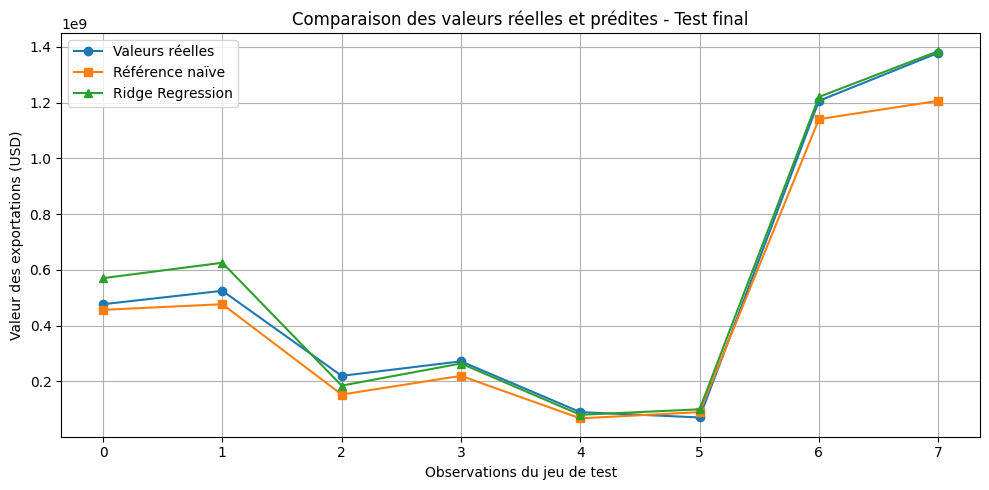

===== ANALYSE DES ERREURS SUR LE TEST =====


,Valeur réelle (USD),Prédiction naïve (USD),Prédiction Ridge (USD),Erreur naïve (USD),Erreur Ridge (USD)
0,4.766231e+08,4.563545e+08,5.700994e+08,2.026859e+07,9.347640e+07
1,5.247493e+08,4.766231e+08,6.253056e+08,4.812622e+07,1.005563e+08
2,2.196994e+08,1.526631e+08,1.846700e+08,6.703633e+07,3.502942e+07
3,2.716955e+08,2.196994e+08,2.639773e+08,5.199607e+07,7.718228e+06
4,8.960929e+07,6.720193e+07,7.994146e+07,2.240736e+07,9.667836e+06
5,7.039637e+07,8.960929e+07,9.967012e+07,1.921292e+07,2.927375e+07
6,1.206158e+09,1.140297e+09,1.220199e+09,6.586131e+07,1.404135e+07
7,1.378072e+09,1.206158e+09,1.384133e+09,1.719144e+08,6.060343e+06


===== INTERPRETATION DES RESULTATS =====
Ridge Regression est plus performant que la référence naïve.
Réduction de la MAE sur le test : 36.63 %

===== ANALYSE DE LA STABILITE =====
MAE Ridge - Validation : 51,062,294.72 USD
MAE Ridge - Test       : 36,977,951.15 USD
MAE naïve - Validation : 57,213,972.35 USD
MAE naïve - Test       : 58,352,900.14 USD

Partie 7 terminée : résultats, graphique et analyse des erreurs.


In [27]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# =====================================================
# 1. FONCTION DE CALCUL DES METRIQUES
# =====================================================

def calculer_metriques(y_reel, y_pred):
    mae = mean_absolute_error(y_reel, y_pred)

    rmse = np.sqrt(mean_squared_error(y_reel, y_pred))

    wape = (
        np.sum(np.abs(np.array(y_reel) - np.array(y_pred)))
        / np.sum(np.abs(y_reel))
    ) * 100

    return mae, rmse, wape


# =====================================================
# 2. CALCUL DES METRIQUES SUR LA VALIDATION
# =====================================================

mae_naive_val, rmse_naive_val, wape_naive_val = calculer_metriques(
    y_val, prediction_naive_val
)

mae_ridge_val, rmse_ridge_val, wape_ridge_val = calculer_metriques(
    y_val, prediction_ridge_val
)


# =====================================================
# 3. CALCUL DES METRIQUES SUR LE TEST FINAL
# =====================================================

mae_naive_test, rmse_naive_test, wape_naive_test = calculer_metriques(
    y_test, prediction_naive_test
)

mae_ridge_test, rmse_ridge_test, wape_ridge_test = calculer_metriques(
    y_test, prediction_ridge_test
)


# =====================================================
# 4. TABLEAU DE SYNTHESE CONFORME A L'ENONCE
# =====================================================

tableau_synthese = pd.DataFrame([
    ["Référence naïve", mae_naive_val, mae_naive_test, "MAE (USD)"],
    ["Ridge Regression", mae_ridge_val, mae_ridge_test, "MAE (USD)"],

    ["Référence naïve", rmse_naive_val, rmse_naive_test, "RMSE (USD)"],
    ["Ridge Regression", rmse_ridge_val, rmse_ridge_test, "RMSE (USD)"],

    ["Référence naïve", wape_naive_val, wape_naive_test, "WAPE (%)"],
    ["Ridge Regression", wape_ridge_val, wape_ridge_test, "WAPE (%)"]

], columns=["Méthode", "Validation", "Test", "Métrique"])

print("===== TABLEAU DE SYNTHESE DES RESULTATS =====")
display(tableau_synthese.round(2))


# =====================================================
# 5. GRAPHIQUE : VALEURS REELLES ET PREDITES SUR LE TEST
# =====================================================

observations = np.arange(len(y_test))

plt.figure(figsize=(10, 5))

plt.plot(
    observations, np.array(y_test),
    marker="o", label="Valeurs réelles"
)

plt.plot(
    observations, prediction_naive_test,
    marker="s", label="Référence naïve"
)

plt.plot(
    observations, prediction_ridge_test,
    marker="^", label="Ridge Regression"
)

plt.title("Comparaison des valeurs réelles et prédites - Test final")
plt.xlabel("Observations du jeu de test")
plt.ylabel("Valeur des exportations (USD)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# =====================================================
# 6. ANALYSE DES ERREURS SUR LE TEST FINAL
# =====================================================

erreurs_naive = np.abs(
    np.array(y_test) - prediction_naive_test
)

erreurs_ridge = np.abs(
    np.array(y_test) - prediction_ridge_test
)

analyse_erreurs = pd.DataFrame({
    "Valeur réelle (USD)": np.array(y_test),
    "Prédiction naïve (USD)": prediction_naive_test,
    "Prédiction Ridge (USD)": prediction_ridge_test,
    "Erreur naïve (USD)": erreurs_naive,
    "Erreur Ridge (USD)": erreurs_ridge
})

print("===== ANALYSE DES ERREURS SUR LE TEST =====")
display(analyse_erreurs.round(2))


# =====================================================
# 7. COMPARAISON DES PERFORMANCES
# =====================================================

print("===== INTERPRETATION DES RESULTATS =====")

if mae_ridge_test < mae_naive_test:
    amelioration = (
        (mae_naive_test - mae_ridge_test) / mae_naive_test
    ) * 100

    print("Ridge Regression est plus performant que la référence naïve.")
    print(f"Réduction de la MAE sur le test : {amelioration:.2f} %")

elif mae_ridge_test > mae_naive_test:
    print("La référence naïve est plus performante que Ridge Regression.")

else:
    print("Les deux méthodes ont la même MAE sur le test.")


# =====================================================
# 8. ANALYSE DE LA STABILITE
# =====================================================

print("\n===== ANALYSE DE LA STABILITE =====")

print(f"MAE Ridge - Validation : {mae_ridge_val:,.2f} USD")
print(f"MAE Ridge - Test       : {mae_ridge_test:,.2f} USD")

print(f"MAE naïve - Validation : {mae_naive_val:,.2f} USD")
print(f"MAE naïve - Test       : {mae_naive_test:,.2f} USD")

print("\nPartie 7 terminée : résultats, graphique et analyse des erreurs.")


## 8. Analyse critique
**Limites des données et de leur représentativité :** La qualité des prévisions dépend de la disponibilité et de la représentativité des données utilisées. La base de données couvre une période historique limitée et ne permet pas nécessairement de représenter toutes les évolutions du commerce extérieur marocain.

Par ailleurs, les exportations agricoles sont influencées par plusieurs facteurs externes qui ne sont pas forcément intégrés dans la base, notamment les conditions climatiques, la disponibilité des ressources en eau, les variations de la demande internationale et les politiques commerciales.

**Limites méthodologiques / risques d'erreurs :** Le modèle Ridge Regression repose sur une relation principalement linéaire entre les variables explicatives et la cible. Il peut donc avoir des difficultés à capturer des évolutions complexes ou des changements soudains dans les exportations.

De plus, les performances observées sur le jeu de test reposent sur un nombre limité de huit observations, ce qui réduit la possibilité de généraliser les résultats à l'ensemble des exportations agricoles marocaines.

Enfin, les prévisions restent sensibles aux fluctuations économiques et commerciales qui ne peuvent pas toujours être anticipées à partir des données historiques.

**Deux améliorations concrètes :** Enrichir la base de données : intégrer de nouvelles variables explicatives telles que les précipitations, la disponibilité en eau, les prix internationaux des produits agricoles et la demande des principaux partenaires commerciaux afin d'améliorer la qualité des prévisions.

Tester d'autres modèles de Machine Learning : comparer Ridge Regression à des modèles non linéaires, comme Random Forest ou XGBoost, afin d'identifier une méthode plus adaptée aux variations des exportations et d'améliorer la précision des prévisions.

## 9. Conclusion
**Réponse explicite à la problématique :** Ce projet avait pour objectif de prévoir la valeur des exportations agricoles marocaines à partir des données historiques en utilisant le Machine Learning. Les résultats obtenus montrent que Ridge Regression est plus performant que la référence naïve. Sur le test final, il réduit la MAE de 58,35 à 36,98 millions USD et le WAPE de 11,02 % à 6,98 %. Ces résultats démontrent l'intérêt du Machine Learning pour améliorer la précision des prévisions des exportations agricoles.

**Objectif atteint ? Quelle valeur commerciale / décisionnelle ?** L'objectif du projet est globalement atteint. Ridge Regression constitue le modèle le plus adapté parmi les deux méthodes comparées. Ses prévisions peuvent aider les entreprises exportatrices et les acteurs du commerce extérieur à anticiper les recettes d'exportation, à mieux planifier leurs activités et à orienter leurs décisions commerciales.

Ainsi, même si les prévisions restent des estimations dépendantes de l'évolution du marché et des facteurs externes, le modèle Ridge représente une meilleure solution prédictive que la référence naïve dans le cadre de cette étude.

## 10. Références, reproduction et dépôt
- **Données :** https://comtradeplus.un.org/
- **Documentation scientifique et technique :** UN Comtrade, documentation : https://comtradeplus.un.org/ · scikit-learn, régression Ridge : https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression-and-classification · Hoerl, A. E. et Kennard, R. W. (1970), « Ridge Regression: Biased Estimation for Nonorthogonal Problems », *Technometrics*, 12(1), 55-67.
- **GitHub :** https://github.com/boussounafatimazahra7649encg-alt/25008040-BOUSSOUNA-CI/tree/3c5c2159bd240762b2da71cc3ff48bfe83c7aeb2/notebooks
- **Réexécution :** `pip install -r requirements.txt` ; exécuter les cellules dans l'ordre.

## Déclaration obligatoire de l'usage de l'IA
| Outil | Usage | Cellules concernées | Vérifications personnelles |
|---|---|---|---|
|Chat gpt  (open AI) | Aide à la rédaction des cellules de texte (sections 3 à 8), à la structuration du dépôt et à des cellules de figures (schéma, figure par produit)

## ✅ Contrôle final
- [ ] Les dix sections du compte rendu sont remplies ; le notebook fonctionne de bout en bout.
- [ ] Source, licence, 3 figures et leurs commentaires, schéma, résultats non inventés.
- [ ] Export PDF du notebook dans `rapport/rapport.pdf`.
- [ ] Six diapositives, vidéo voix + écran de 60–90 s en MP4, 720p minimum.
- [ ] `README.md`, `requirements.txt`, `DECLARATION_IA.md` et ressources dans GitHub.
- [ ] Au moins 3 commits durant les 2 heures et tag `remise-finale`.
- [ ] Remise officielle : https://forms.gle/SmfW9kbcNbsz4Q8a7